## import the segment wise absolute correlation matrices

In [13]:
from pathlib import Path
import pandas as pd

abs_segment_base = Path('correlation_matrices_segment_wise_absolute')
matrix_files = list(abs_segment_base.rglob('*.csv'))

if matrix_files:
    sample = pd.read_csv(matrix_files[0], index_col=0)
    print(f"Found {len(matrix_files)} absolute matrices. Sample shape: {sample.shape}")


Found 2632 absolute matrices. Sample shape: (19, 19)


## filter the subjects for our study

In [14]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

# Filter subjects
subject_ids = [64, 65, 69, 70, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 94, 96, 103]
formatted_subjects = [f"sub-NORB{sid:05d}" for sid in subject_ids]

# Extract first 12 segments for session 1
n_segments = 12
subject_matrices = {}

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        print(f"Warning: directory not found for {subj}")
        continue
        
    csv_files = sorted(subj_dir.glob('*.csv'))
    if len(csv_files) < n_segments:
        print(f"Warning: {subj} has less than {n_segments} segments")
        
    matrices = []
    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        matrices.append(df.values)
        
    if matrices:
        avg_matrix = np.mean(matrices, axis=0)
        subject_matrices[subj] = pd.DataFrame(avg_matrix, index=df.index, columns=df.columns)
        
print(f"Processed {len(subject_matrices)} subjects")


Processed 20 subjects


## plotting raw correlation data

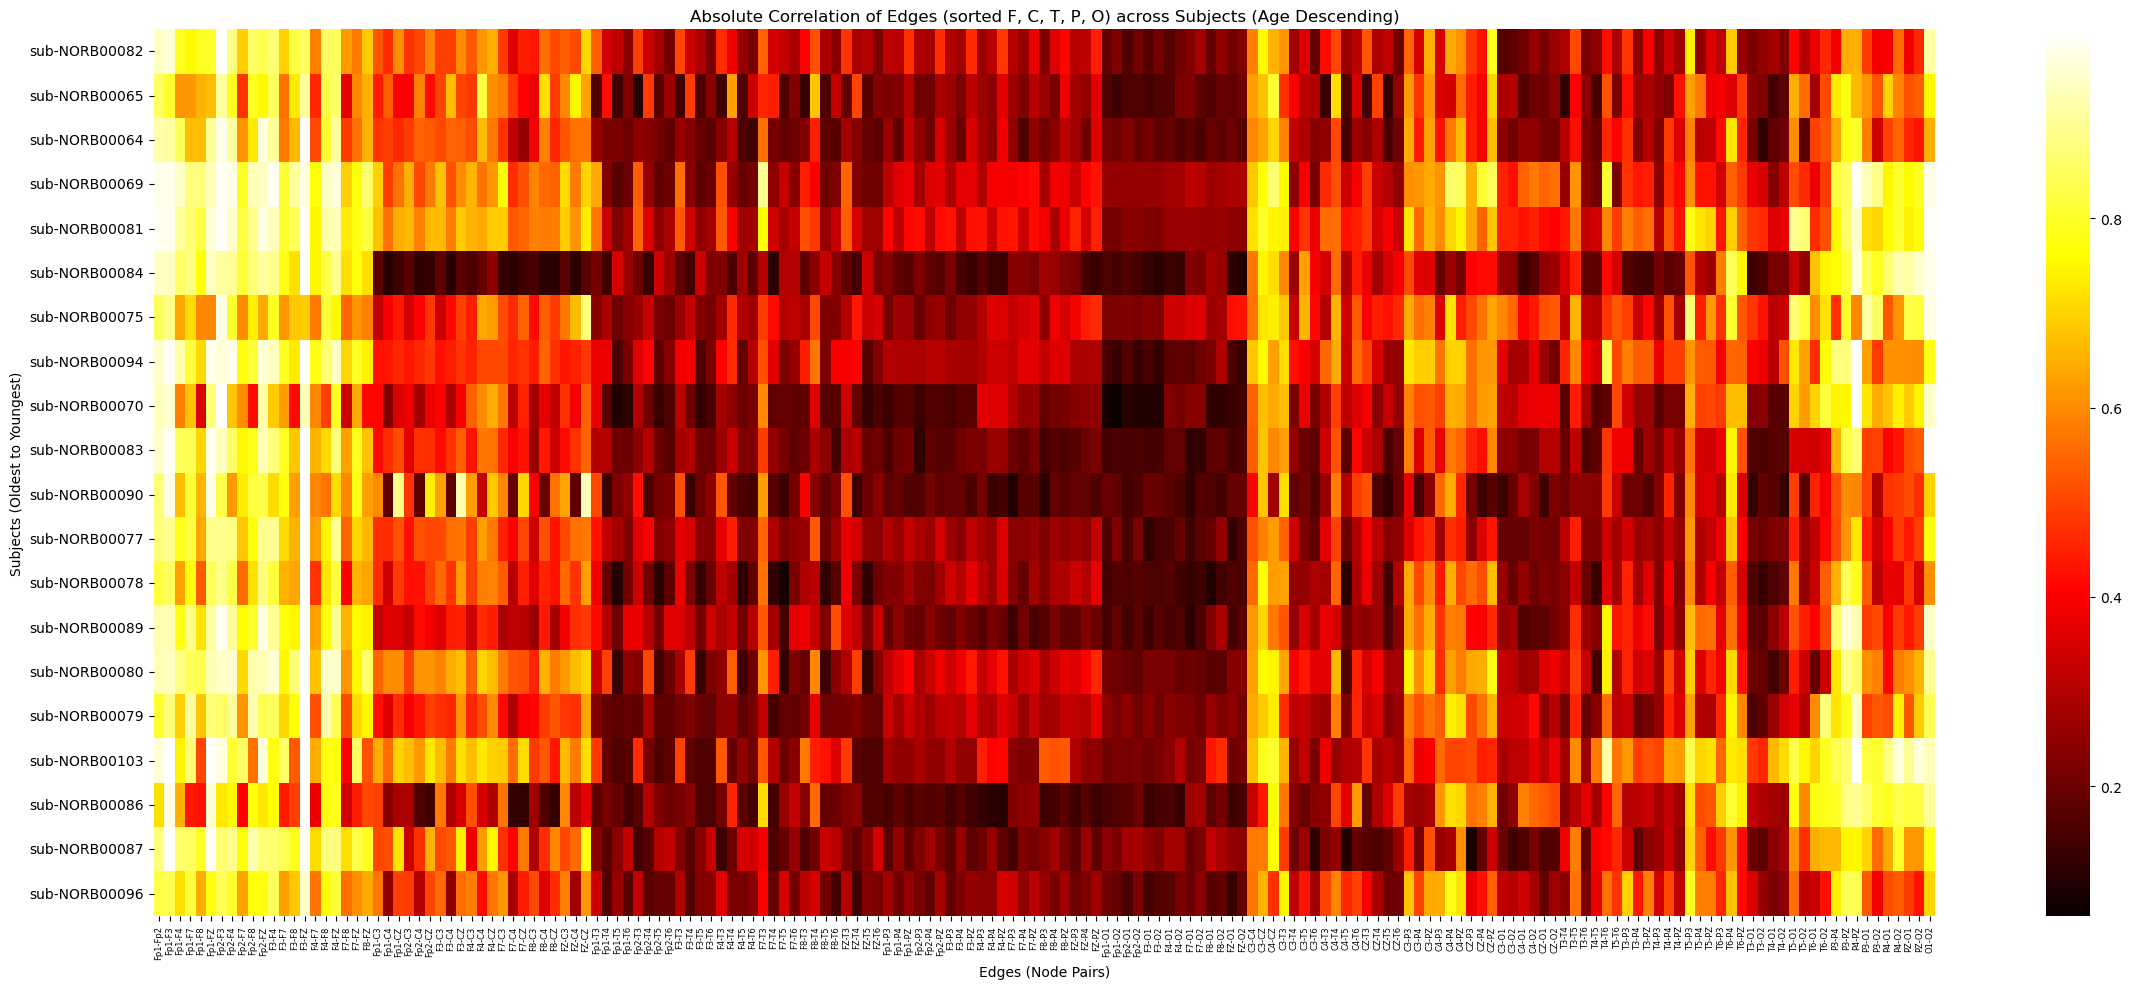

In [15]:
# Hardcoded edge order (F, C, T, P, O pairs)
edge_labels = [
    'Fp1-Fp2', 'Fp1-F3', 'Fp1-F4', 'Fp1-F7', 'Fp1-F8', 'Fp1-FZ', 'Fp2-F3',
    'Fp2-F4', 'Fp2-F7', 'Fp2-F8', 'Fp2-FZ', 'F3-F4', 'F3-F7', 'F3-F8', 'F3-FZ',
    'F4-F7', 'F4-F8', 'F4-FZ', 'F7-F8', 'F7-FZ', 'F8-FZ', 'Fp1-C3', 'Fp1-C4',
    'Fp1-CZ', 'Fp2-C3', 'Fp2-C4', 'Fp2-CZ', 'F3-C3', 'F3-C4', 'F3-CZ', 'F4-C3',
    'F4-C4', 'F4-CZ', 'F7-C3', 'F7-C4', 'F7-CZ', 'F8-C3', 'F8-C4', 'F8-CZ',
    'FZ-C3', 'FZ-C4', 'FZ-CZ', 'Fp1-T3', 'Fp1-T4', 'Fp1-T5', 'Fp1-T6',
    'Fp2-T3', 'Fp2-T4', 'Fp2-T5', 'Fp2-T6', 'F3-T3', 'F3-T4', 'F3-T5', 'F3-T6',
    'F4-T3', 'F4-T4', 'F4-T5', 'F4-T6', 'F7-T3', 'F7-T4', 'F7-T5', 'F7-T6',
    'F8-T3', 'F8-T4', 'F8-T5', 'F8-T6', 'FZ-T3', 'FZ-T4', 'FZ-T5', 'FZ-T6',
    'Fp1-P3', 'Fp1-P4', 'Fp1-PZ', 'Fp2-P3', 'Fp2-P4', 'Fp2-PZ', 'F3-P3',
    'F3-P4', 'F3-PZ', 'F4-P3', 'F4-P4', 'F4-PZ', 'F7-P3', 'F7-P4', 'F7-PZ',
    'F8-P3', 'F8-P4', 'F8-PZ', 'FZ-P3', 'FZ-P4', 'FZ-PZ', 'Fp1-O1', 'Fp1-O2',
    'Fp2-O1', 'Fp2-O2', 'F3-O1', 'F3-O2', 'F4-O1', 'F4-O2', 'F7-O1', 'F7-O2',
    'F8-O1', 'F8-O2', 'FZ-O1', 'FZ-O2', 'C3-C4', 'C3-CZ', 'C4-CZ', 'C3-T3',
    'C3-T4', 'C3-T5', 'C3-T6', 'C4-T3', 'C4-T4', 'C4-T5', 'C4-T6', 'CZ-T3',
    'CZ-T4', 'CZ-T5', 'CZ-T6', 'C3-P3', 'C3-P4', 'C3-PZ', 'C4-P3', 'C4-P4',
    'C4-PZ', 'CZ-P3', 'CZ-P4', 'CZ-PZ', 'C3-O1', 'C3-O2', 'C4-O1', 'C4-O2',
    'CZ-O1', 'CZ-O2', 'T3-T4', 'T3-T5', 'T3-T6', 'T4-T5', 'T4-T6', 'T5-T6',
    'T3-P3', 'T3-P4', 'T3-PZ', 'T4-P3', 'T4-P4', 'T4-PZ', 'T5-P3', 'T5-P4',
    'T5-PZ', 'T6-P3', 'T6-P4', 'T6-PZ', 'T3-O1', 'T3-O2', 'T4-O1', 'T4-O2',
    'T5-O1', 'T5-O2', 'T6-O1', 'T6-O2', 'P3-P4', 'P3-PZ', 'P4-PZ', 'P3-O1',
    'P3-O2', 'P4-O1', 'P4-O2', 'PZ-O1', 'PZ-O2', 'O1-O2',
]

# Load ages and sort subjects descending (oldest top, youngest bottom)
ages_df = pd.read_csv('age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)].copy()
ages_filtered = ages_filtered.sort_values('age_acq_time', ascending=False)

sorted_subject_labels = ages_filtered['label'].tolist()
sorted_subjects = [label.split('_')[0] for label in sorted_subject_labels]

# Prepare data for heatmap
heatmap_data = []
valid_subjects = []

for subj in sorted_subjects:
    if subj in subject_matrices:
        df_matrix = subject_matrices[subj]
        row_data = [df_matrix.loc[e.split('-')[0], e.split('-')[1]] for e in edge_labels]
        heatmap_data.append(row_data)
        valid_subjects.append(subj)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(24, 10))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=valid_subjects)
plt.title('Absolute Correlation of Edges (sorted F, C, T, P, O) across Subjects (Age Descending)')
plt.xlabel('Edges (Node Pairs)')
plt.ylabel('Subjects (Oldest to Youngest)')
plt.xticks(rotation=90, fontsize=6)
plt.tight_layout()
plt.show()


## edge-wise weighted jaccard index
for each pair of subjects and for each of the 171 edges, it:
1. calculates the jaccard index `min(A, B) / max(A, B)` for that specific edge on a given segment.
2. averages this edge-specific jaccard index across all 12 segments.

the result is a dictionary mapping each subject pair `(subj1, subj2)` to an array of 171 average jaccard index values (one for each edge).


In [16]:
# Load all 12 segment matrices for the valid subjects to calculate the Jaccard Index
subject_segments = {}
for subj in valid_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    csv_files = sorted(subj_dir.glob('*.csv'))[:12]
    
    seg_list = []
    for csv_file in csv_files:
        df = pd.read_csv(csv_file, index_col=0)
        # Extract the exact 171 edges defined earlier
        edge_vals = [df.loc[e.split('-')[0], e.split('-')[1]] for e in edge_labels]
        seg_list.append(np.array(edge_vals))
    subject_segments[subj] = seg_list

# Calculate edge-wise Jaccard index for all subject pairs (20C2)
subject_pairs = list(combinations(valid_subjects, 2))
pair_edgewise_jaccard = {}

for subj1, subj2 in subject_pairs:
    segment_edge_jaccards = []
    
    for k in range(12):
        u = subject_segments[subj1][k]  # Array of 171 edges for segment k
        v = subject_segments[subj2][k]
        
        # Edge-wise Jaccard: min(u_i, v_i) / max(u_i, v_i) for each edge
        mins = np.minimum(u, v)
        maxs = np.maximum(u, v)
        
        # Handle division by zero per edge securely
        with np.errstate(divide='ignore', invalid='ignore'):
            j_score = np.where(maxs != 0, mins / maxs, 0)
            
        segment_edge_jaccards.append(j_score)
        
    # Average across the 12 segments for this pair, resulting in 171 averaged values
    pair_edgewise_jaccard[(subj1, subj2)] = np.mean(segment_edge_jaccards, axis=0)

print(f"Calculated edge-wise Jaccard indices for {len(pair_edgewise_jaccard)} subject pairs.")
print(f"Each pair has {len(list(pair_edgewise_jaccard.values())[0])} values corresponding to the edges.")


Calculated edge-wise Jaccard indices for 190 subject pairs.
Each pair has 171 values corresponding to the edges.


## plot the jaccard index

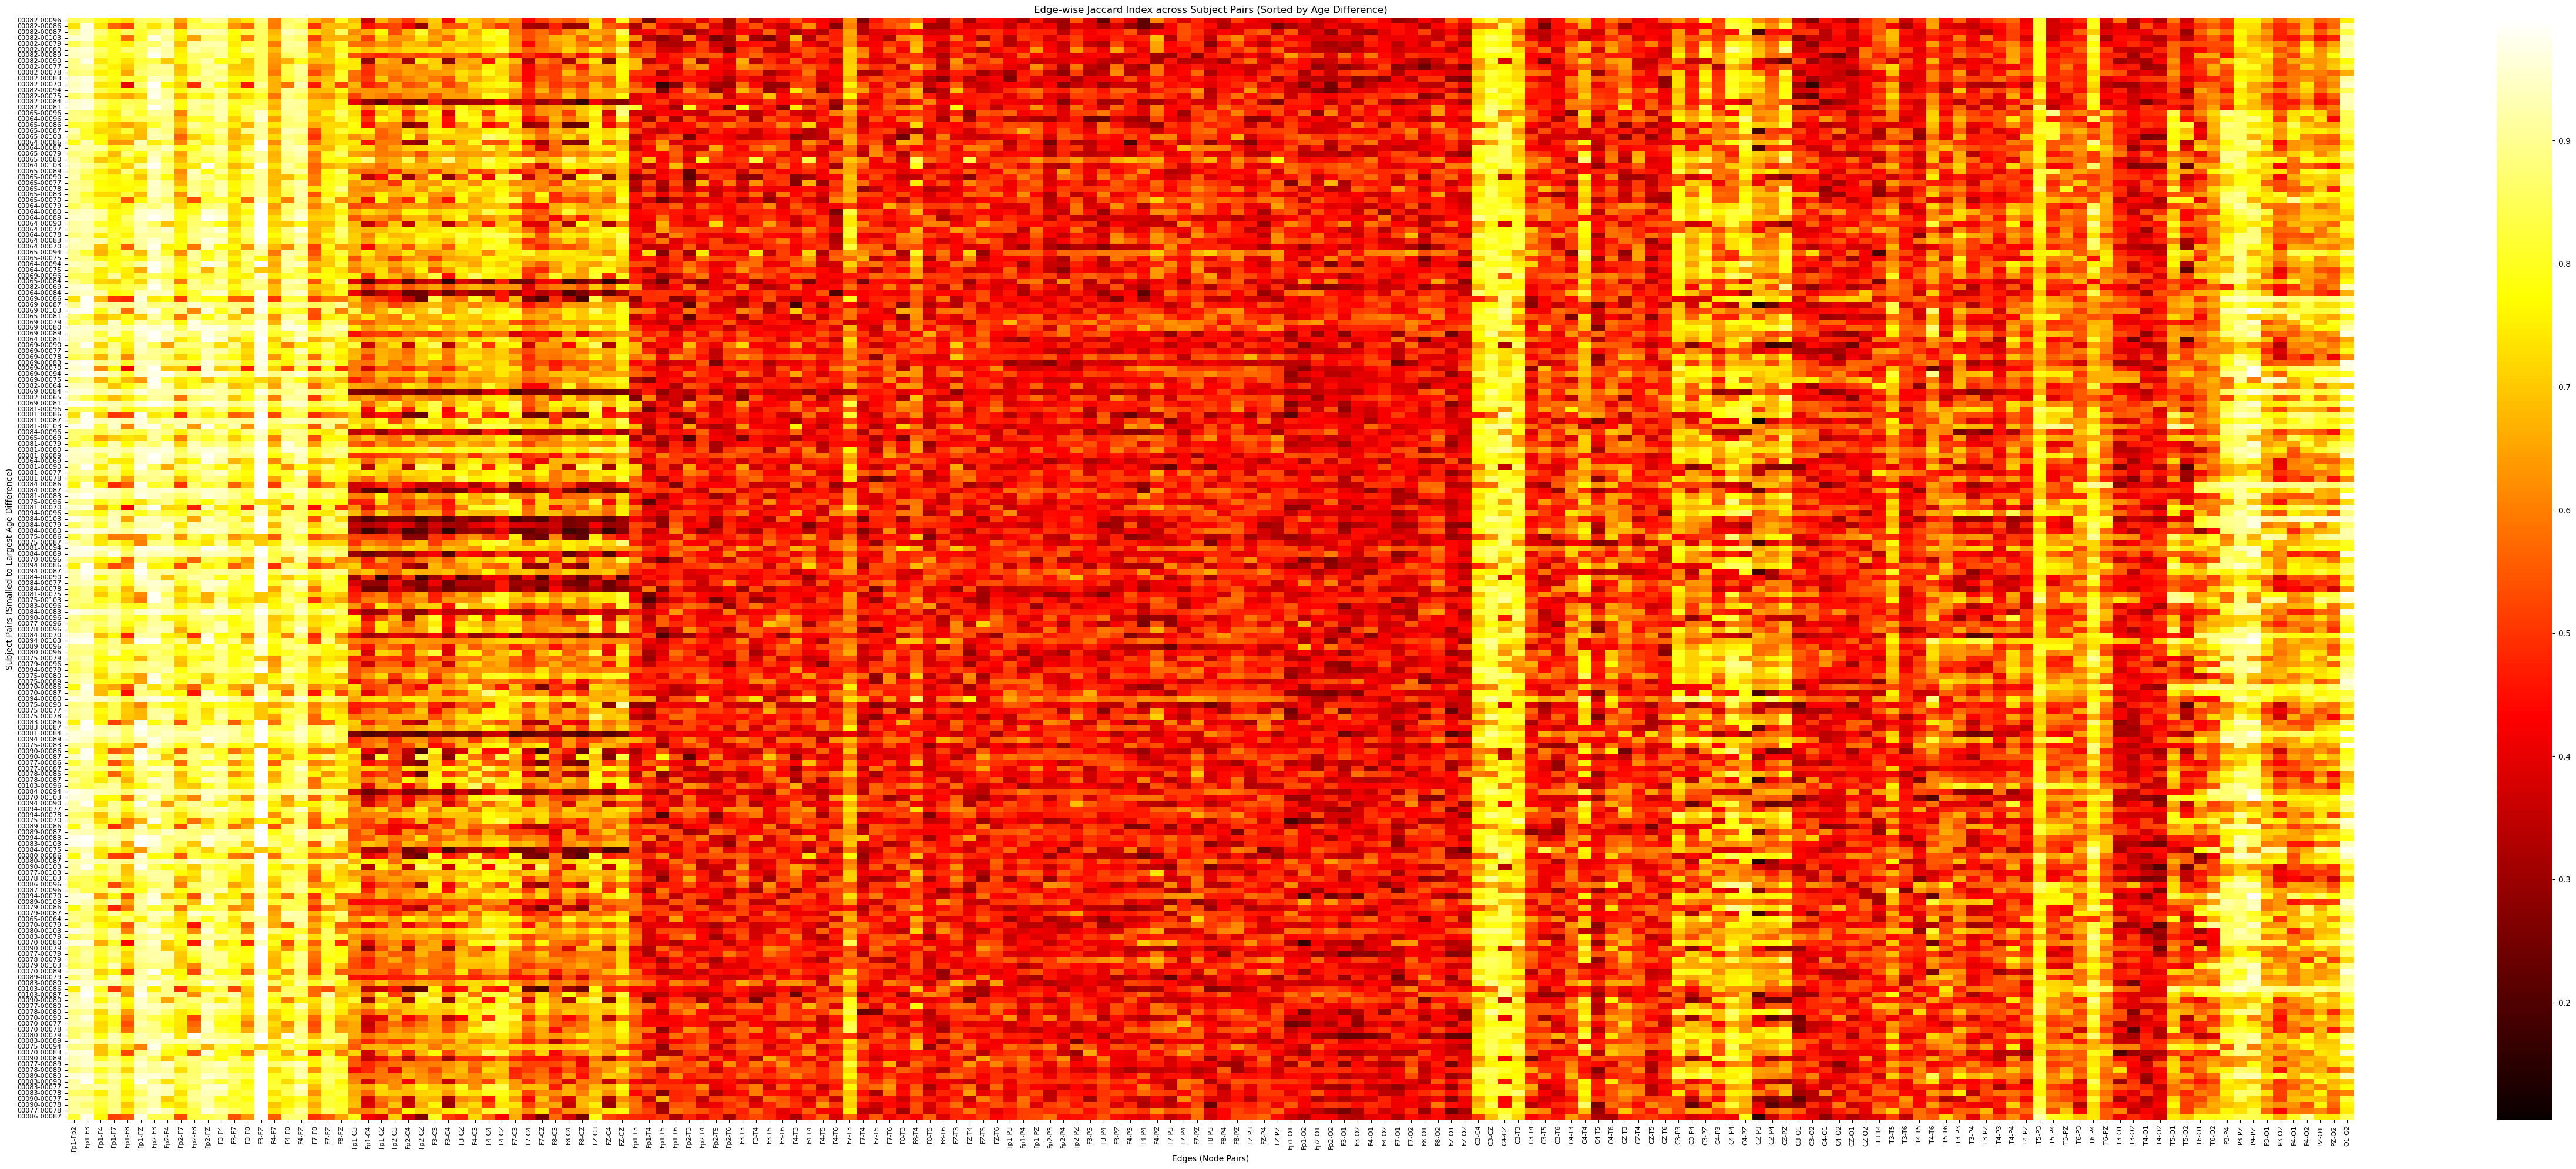

In [17]:
# Create a dictionary mapping subject ID to their age
age_dict = {}
for idx, row in ages_filtered.iterrows():
    subj = row['label'].split('_')[0]
    age_dict[subj] = row['age_acq_time']

# Compute absolute age differences for each subject pair
pair_age_diffs = {}
for subj1, subj2 in subject_pairs:
    diff = abs(age_dict[subj1] - age_dict[subj2])
    pair_age_diffs[(subj1, subj2)] = diff

# Sort subject pairs by age difference (descending: largest difference at top, smallest at bottom)
sorted_pairs = sorted(pair_age_diffs.keys(), key=lambda p: pair_age_diffs[p], reverse=True)

# Prepare data for heatmap
heatmap_data = []
yticklabels = []

for pair in sorted_pairs:
    heatmap_data.append(pair_edgewise_jaccard[pair])
    # Create a compact label for the y-axis
    s1 = pair[0].replace('sub-NORB', '')
    s2 = pair[1].replace('sub-NORB', '')
    yticklabels.append(f"{s1}-{s2}")

heatmap_data = np.array(heatmap_data)

# Plot the heatmap with a wide figure size to stretch the cells horizontally
plt.figure(figsize=(50, 20)) 
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=yticklabels)
plt.title('Edge-wise Jaccard Index across Subject Pairs (Sorted by Age Difference)')
plt.xlabel('Edges (Node Pairs)')
plt.ylabel('Subject Pairs (Smalled to Largest Age Difference)')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


## Region-wise Statistical Summary of Jaccard Index Values

This cell calculates and displays a grouped bar plot showing the percentage of Jaccard index values exceeding **0.75** and **0.90** for each specific brain region connection type (F-F, F-C, F-T, ..., O-O).

Connection   | Total Values   | % > 0.75   | % > 0.90  
--------------------------------------------------------
F-F          | 3,990          | 75.84      | 29.40     
F-C          | 3,990          | 13.41      | 0.03      
F-T          | 5,320          | 0.90       | 0.00      
F-P          | 3,990          | 0.03       | 0.00      
F-O          | 2,660          | 0.00       | 0.00      
C-C          | 570            | 69.65      | 1.40      
C-T          | 2,280          | 6.49       | 0.04      
C-P          | 1,710          | 22.34      | 0.23      
C-O          | 1,140          | 0.09       | 0.00      
T-T          | 1,140          | 2.81       | 0.00      
T-P          | 2,280          | 12.89      | 0.31      
T-O          | 1,520          | 6.25       | 0.39      
P-P          | 570            | 71.23      | 18.95     
P-O          | 1,140          | 21.23      | 2.02      
O-O          | 190            | 77.89      | 30.00     


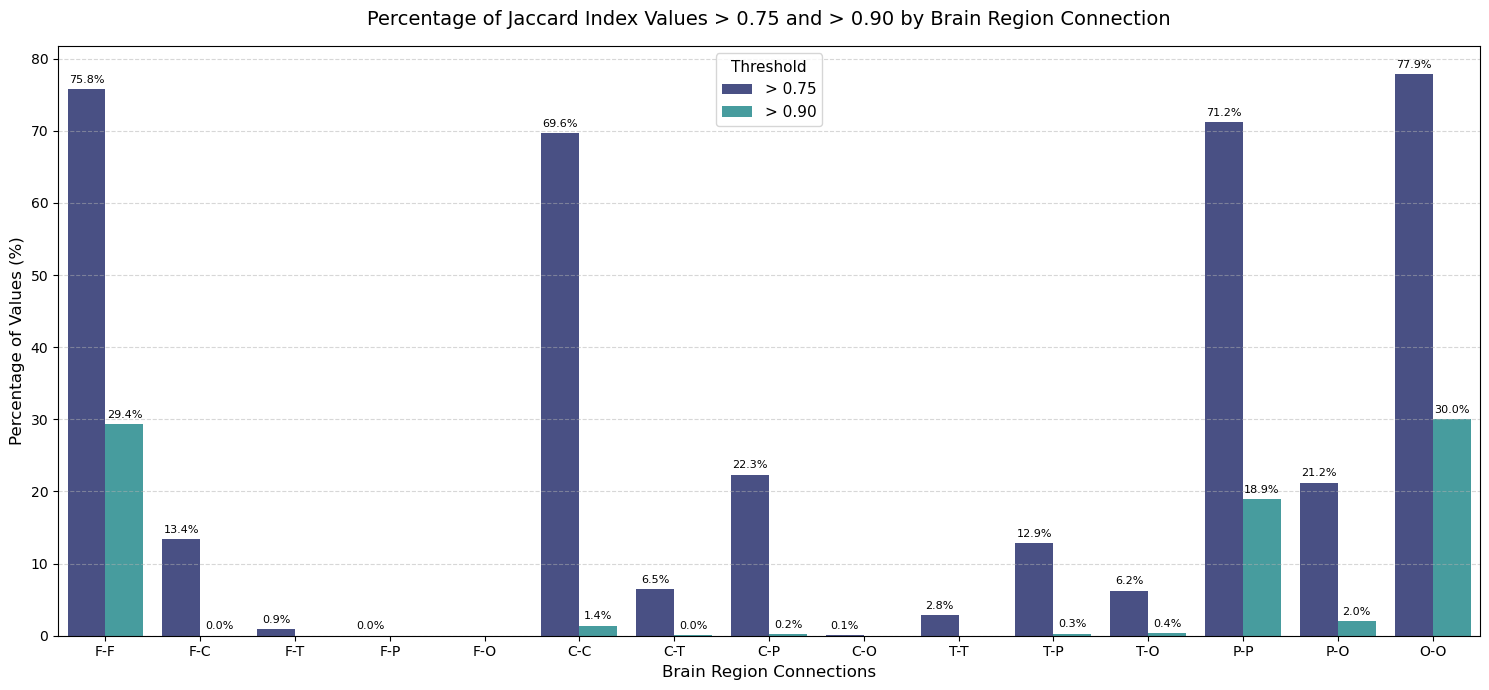

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define region order and canonical mapping
region_order = {'F': 0, 'C': 1, 'T': 2, 'P': 3, 'O': 4}

def get_region_pair(edge):
    u, v = edge.split('-')
    r1, r2 = u[0], v[0]
    if region_order.get(r1, 99) <= region_order.get(r2, 99):
        return f"{r1}-{r2}"
    else:
        return f"{r2}-{r1}"

# 2. Map every edge in edge_labels to its canonical region pair
region_groups = ['F-F', 'F-C', 'F-T', 'F-P', 'F-O', 
                 'C-C', 'C-T', 'C-P', 'C-O', 
                 'T-T', 'T-P', 'T-O', 
                 'P-P', 'P-O', 
                 'O-O']

region_values = {cat: [] for cat in region_groups}

for idx, edge in enumerate(edge_labels):
    cat = get_region_pair(edge)
    if cat in region_values:
        col_vals = heatmap_data[:, idx]
        region_values[cat].extend(col_vals)

# 3. Calculate percentages > 0.75 and > 0.90
stats_data = []

print(f"{'Connection':<12} | {'Total Values':<14} | {'% > 0.75':<10} | {'% > 0.90':<10}")
print("-" * 56)

for cat in region_groups:
    vals = np.array(region_values[cat])
    total = len(vals)
    if total > 0:
        pct_75 = (np.sum(vals > 0.75) / total) * 100.0
        pct_90 = (np.sum(vals > 0.90) / total) * 100.0
    else:
        pct_75, pct_90 = 0.0, 0.0
        
    val_str = f"{total:,}"
    print(f"{cat:<12} | {val_str:<14} | {pct_75:<10.2f} | {pct_90:<10.2f}")
    
    stats_data.append({'Region Pair': cat, 'Threshold': '> 0.75', 'Percentage': pct_75})
    stats_data.append({'Region Pair': cat, 'Threshold': '> 0.90', 'Percentage': pct_90})

df_stats = pd.DataFrame(stats_data)

# 4. Plot the grouped bar chart
plt.figure(figsize=(15, 7))
ax = sns.barplot(data=df_stats, x='Region Pair', y='Percentage', hue='Threshold', palette='mako')

plt.title('Percentage of Jaccard Index Values > 0.75 and > 0.90 by Brain Region Connection', fontsize=14, pad=15)
plt.xlabel('Brain Region Connections', fontsize=12)
plt.ylabel('Percentage of Values (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels above the bars for clear readability
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 3),
                    textcoords='offset points',
                    fontsize=8, rotation=0)

plt.legend(title='Threshold', fontsize=11, title_fontsize=11)
plt.tight_layout()
plt.show()